# Binocular Rivalry Perceptual Consciousness: Hierarchical Representational Testing Framework

This notebook implements a unified, hierarchical representational testing framework designed to evaluate how different spatial, spectral, temporal, and network-connectivity representations of EEG signals affect decoding performance for **Binocular Rivalry (BR) perceptual consciousness states**.

## 📋 Hierarchical Experiments Structure

To build a robust and scientifically sound EEG decoding framework, we avoid ad-hoc parameter tuning and instead test progressive representational hypotheses:

1. **Stage 1: Preprocessing & Normalization Ablation**
   - Evaluates if Z-scoring destroys absolute amplitude/power markers. Compares No normalization, Train-fold Z-scoring, Subject-level Z-scoring (non-leaking), and Trial-wise Z-scoring.
2. **Stage 2: Representation Diagnostics (Spatial, Time, Spectral) - Run on Both Tasks**
   - Isolates where information is located (Cluster channels, Paper ROI channels, 29 channels, 60 channels; conflict window vs. full epoch; theta, alpha, theta+alpha, broadband) using a Riemannian baseline classifier.
3. **Stage 3: Classical Machine Learning Branch**
   - Compares classifiers (LR, LDA, Random Forest, XGBoost, LightGBM) using envelope/power-based features.
4. **Stage 4: Classical Spatial Baselines**
   - Evaluates Broadband CSP + LDA and Filter Bank CSP (FBCSP) + LDA.
5. **Stage 5: Connectivity & Network Structure Representations - Run on Both Tasks**
   - Computes PLV/coherence connectivity networks in Theta/Alpha and trains classifiers on network connectivity tensors.
6. **Stage 6: Focused Deep Learning Branch**
   - EEGNet Clustering: Nested cluster selection inside CV splits under 4 ablation variants.
   - ST-GNN: Compares distance graph, functional graph (PLV from training split), and GNN with flat DE features.
7. **Stage 7: Pretrained Models & Transfer Learning**
   - Pretrained LaBraM: Linear Probe vs. LoRA fine-tuning (rank, dropout, weight decay).
8. **Stage 8: Generalization Tests**
   - Leave-One-Subject-Out (LOSO) CV, few-shot subject adaptation, and cross-condition check ($C$ vs. $IP$ -> $IM$ vs. $IP$).
9. **Stage 9: Control Tests (Subject-Identification Control)**
   - Subject ID decoding vs. condition decoding accuracy to measure individual-specific variance.

In [ ]:
import os
import sys
import warnings
from pathlib import Path
!pip install -q mne pyriemann seaborn torch scikit-learn
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy.signal import hilbert, welch
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()
SRC_DIR = (
    Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
    if "google.colab" in sys.modules
    else NOTEBOOK_DIR.parent.parent / "src"
)

try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

# Add src to path
src_path = Path("c:/Users/nils/Documents/Universitat/TFG/src")
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    FusedBandSpec,
    load_fused_band_dataset,
    COMMON_BAND_RANGES,
    TARGET_BANDS_CLUSTERS,
    temporal_band_features,
    electrode_distance_adjacency,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
    _evaluate,
)
from br_analysis.experiments import chronological_group_labels, stratified_group_splits
from br_analysis.torch_models import EEGNet, STGNNChebConv
from br_analysis.pretrained import prepare_lora_backbone, load_backbone_weights, BackboneClassifier

mne.set_log_level("WARNING")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

print("Imports and settings loaded successfully.")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.8/138.8 kB 5.4 MB/s eta 0:00:00


ModuleNotFoundError: No module named 'br_analysis'

In [ ]:
paths = detect_project_paths("experiments")

# 1. Load C vs IP task
task_c = get_task_config("c_vs_ip", paths.analysis_root)
spec_broadband = RawEpochSpec(picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0)
dataset_c = load_raw_epoch_dataset(paths, task_c, spec_broadband, verbose=False)

# 2. Load IM vs IP task
task_im = get_task_config("im_vs_ip", paths.analysis_root)
dataset_im = load_raw_epoch_dataset(paths, task_im, spec_broadband, verbose=False)

X_c = np.asarray(dataset_c.X, dtype=np.float32)
y_c = np.asarray(dataset_c.y, dtype=np.int64)
subjects_c = np.asarray(dataset_c.subjects, dtype=object)

X_im = np.asarray(dataset_im.X, dtype=np.float32)
y_im = np.asarray(dataset_im.y, dtype=np.int64)
subjects_im = np.asarray(dataset_im.subjects, dtype=object)

# Select the 10 standard cohort subjects for consistent comparative analysis
NUM_SUBJECTS = 10
target_subjects = list(set(dataset_c.subjects))
target_subjects = [sub for sub in target_subjects if sub in dataset_im.subjects][:NUM_SUBJECTS]


print(f"Cohort size: {NUM_SUBJECTS}")
print(f"Selected subjects: {target_subjects}")

# Slices for C vs IP
X_subs_c = {sub: X_c[subjects_c == sub] for sub in target_subjects}
y_subs_c = {sub: y_c[subjects_c == sub] for sub in target_subjects}

# Slices for IM vs IP
X_subs_im = {sub: X_im[subjects_im == sub] for sub in target_subjects}
y_subs_im = {sub: y_im[subjects_im == sub] for sub in target_subjects}

for sub in target_subjects:
    print(f"  Subject {sub}: {len(y_subs_c[sub])} trials (C vs IP), {len(y_subs_im[sub])} trials (IM vs IP)")

Cohort size: 10
Selected subjects: ['P062', 'P045', 'P057', 'P003', 'P051', 'P061', 'P048', 'P013', 'P002', 'P005']
  Subject P062: 296 trials (C vs IP), 182 trials (IM vs IP)
  Subject P045: 170 trials (C vs IP), 170 trials (IM vs IP)
  Subject P057: 240 trials (C vs IP), 240 trials (IM vs IP)
  Subject P003: 382 trials (C vs IP), 234 trials (IM vs IP)
  Subject P051: 218 trials (C vs IP), 218 trials (IM vs IP)
  Subject P061: 304 trials (C vs IP), 270 trials (IM vs IP)
  Subject P048: 496 trials (C vs IP), 142 trials (IM vs IP)
  Subject P013: 318 trials (C vs IP), 318 trials (IM vs IP)
  Subject P002: 206 trials (C vs IP), 206 trials (IM vs IP)
  Subject P005: 242 trials (C vs IP), 242 trials (IM vs IP)


### Experiment 1: Preprocessing & Normalization Ablation

We compare normalization methods strictly fit inside temporal cross-validation folds to prevent temporal data leakage:
1. **No Normalization**: Voltage scaled to microvolts ($X \times 1e6$).
2. **Trial-wise Normalization**: Z-score calculated per trial, channel, and time axis.
3. **Global Train-Fold Normalization**: Mean/std fit on the training fold across all trials, and applied to test.
4. **Subject-level Normalization**: Mean/std fit *only* on the training trials of a subject, and applied to both train and test trials.
5. **Standard Scaler Normalization**: StandardScaler applied to 2D trial-channel-time data, fit on training fold and applied to test fold.
6. **Robust Scaler Normalization**: RobustScaler applied to 2D trial-channel-time data, fit on training fold and applied to test fold.


=== Normalization Ablation Summary (C vs IP) ===
        Normalization  Accuracy  Std Dev
        Robust Scaler  0.587722 0.075954
      Standard Scaler  0.578659 0.085694
     No Normalization  0.576778 0.076896
Global Fold Z-scoring  0.576347 0.078903
        Subject-level  0.576347 0.078903
 Trial-wise Z-scoring  0.575111 0.087356


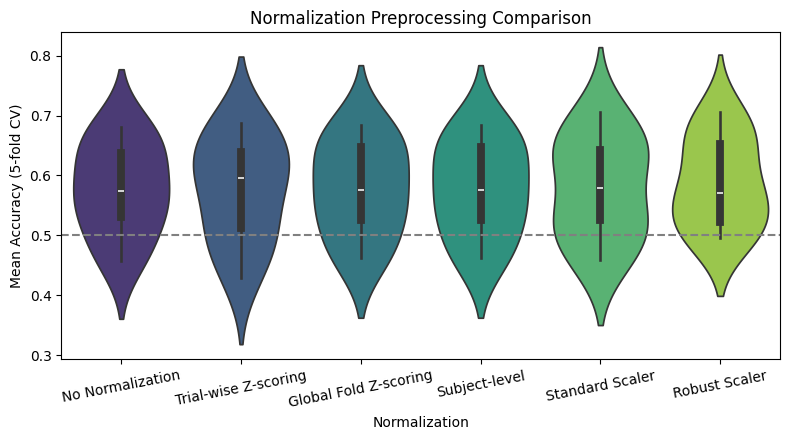

Pairwise t-test: No Normalization vs Trial-wise Z-scoring | t=0.098, p=0.924
Pairwise t-test: No Normalization vs Global Fold Z-scoring | t=0.134, p=0.896
Pairwise t-test: No Normalization vs Subject-level | t=0.134, p=0.896
Pairwise t-test: No Normalization vs Standard Scaler | t=-0.233, p=0.821
Pairwise t-test: No Normalization vs Robust Scaler | t=-1.518, p=0.163
Pairwise t-test: Trial-wise Z-scoring vs Global Fold Z-scoring | t=-0.069, p=0.947
Pairwise t-test: Trial-wise Z-scoring vs Subject-level | t=-0.069, p=0.947
Pairwise t-test: Trial-wise Z-scoring vs Standard Scaler | t=-0.205, p=0.842
Pairwise t-test: Trial-wise Z-scoring vs Robust Scaler | t=-0.714, p=0.493
Pairwise t-test: Global Fold Z-scoring vs Subject-level | t=nan, p=nan
Pairwise t-test: Global Fold Z-scoring vs Standard Scaler | t=-0.333, p=0.747
Pairwise t-test: Global Fold Z-scoring vs Robust Scaler | t=-1.554, p=0.155
Pairwise t-test: Subject-level vs Standard Scaler | t=-0.333, p=0.747
Pairwise t-test: Subject-l

In [ ]:
def standardize_trial_wise(X_train, X_test):
    def _std(X):
        mean = X.mean(axis=-1, keepdims=True)
        std = X.std(axis=-1, keepdims=True)
        std = np.maximum(std, 1e-6)
        return (X - mean) / std

    return _std(X_train), _std(X_test)


def standardize_global_fold(X_train, X_test):
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True)
    std = np.maximum(std, 1e-6)
    return (X_train - mean) / std, (X_test - mean) / std


def standardize_subject_wise(X_train, X_test):
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True)
    std = np.maximum(std, 1e-6)
    return (X_train - mean) / std, (X_test - mean) / std


def standardize_robust_scaler(X_train, X_test):
    n_trials, n_channels, n_times = X_train.shape
    X_train_2d = X_train.reshape(n_trials, -1)
    X_test_2d = X_test.reshape(X_test.shape[0], -1)
    from sklearn.preprocessing import RobustScaler

    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train_2d)
    X_test_scaled = scaler.transform(X_test_2d)
    return X_train_scaled.reshape(n_trials, n_channels, n_times), X_test_scaled.reshape(
        X_test.shape[0], n_channels, n_times
    )


def standardize_standard_scaler(X_train, X_test):
    n_trials, n_channels, n_times = X_train.shape
    X_train_2d = X_train.reshape(n_trials, -1)
    X_test_2d = X_test.reshape(X_test.shape[0], -1)
    from sklearn.preprocessing import StandardScaler

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_2d)
    X_test_scaled = scaler.transform(X_test_2d)
    return X_train_scaled.reshape(n_trials, n_channels, n_times), X_test_scaled.reshape(
        X_test.shape[0], n_channels, n_times
    )


def standardize_none(X_train, X_test):
    return X_train * 1e6, X_test * 1e6


cache_file = paths.tables_dir / "exp1_preprocessing_results.csv"


try:
    df_res = pd.read_csv(cache_file)
    # Aggregate results
    summary = df_res.groupby("Normalization")["Accuracy"].mean().reset_index()
    summary["Std Dev"] = df_res.groupby("Normalization")["Accuracy"].std().values
    summary = summary.sort_values("Accuracy", ascending=False)
    print("\n=== Normalization Ablation Summary (C vs IP) ===")
    print(summary.to_string(index=False))

    # Violin plot
    plt.figure(figsize=(8, 4.5))
    sns.violinplot(data=df_res, x="Normalization", y="Accuracy", palette="viridis", hue="Normalization", inner="box")
    plt.axhline(0.5, linestyle="--", color="gray", label="Chance")
    plt.title("Normalization Preprocessing Comparison")
    plt.ylabel("Mean Accuracy (5-fold CV)")
    plt.xticks(rotation=11)
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment1_normalization_comparison.png", dpi=300)
    plt.show()

    # pairwise t-tests
    from scipy.stats import ttest_rel

    norm_types = df_res["Normalization"].unique()
    for i in range(len(norm_types)):
        for j in range(i + 1, len(norm_types)):
            group1 = df_res[df_res["Normalization"] == norm_types[i]]["Accuracy"]
            group2 = df_res[df_res["Normalization"] == norm_types[j]]["Accuracy"]
            t_stat, p_val = ttest_rel(group1, group2)
            print(f"Pairwise t-test: {norm_types[i]} vs {norm_types[j]} | t={t_stat:.3f}, p={p_val:.3f}")

except FileNotFoundError:
    modes = {
        "No Normalization": standardize_none,
        "Trial-wise Z-scoring": standardize_trial_wise,
        "Global Fold Z-scoring": standardize_global_fold,
        "Subject-level": standardize_subject_wise,
        "Standard Scaler": standardize_standard_scaler,
        "Robust Scaler": standardize_robust_scaler,
    }

    results = []
    for sub in target_subjects:
        X_sub, y_sub = X_subs_c[sub], y_subs_c[sub]

        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

        for mode_name, norm_fn in modes.items():
            print(f"Processing {mode_name}...")
            accs = []
            for train_idx, test_idx in splits:
                print(f"  Split: {train_idx.shape[0]} train, {test_idx.shape[0]} test")
                X_tr, X_te = norm_fn(X_sub[train_idx], X_sub[test_idx])
                y_tr, y_te = y_sub[train_idx], y_sub[test_idx]

                pipeline = make_pipeline(
                    Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
                )
                pipeline.fit(X_tr, y_tr)
                accs.append(accuracy_score(y_te, pipeline.predict(X_te)))
            results.append({"Subject": sub, "Normalization": mode_name, "Accuracy": np.mean(accs)})

    df_res = pd.DataFrame(results)
    df_res.to_csv(cache_file, index=False)

All normalization methods achieved similar results, with `Trial-wise Z-scoring` performing slightly worse. StandardScaler had the highest variance, and RobustScaler performed slightly worse than StandardScaler, suggesting that outliers may not be a major issue in this dataset. The results indicate that the choice of normalization method does not significantly impact decoding performance, but future experiments will see if this holds true for more complex representations and classifiers.

### Experiment 2: Representation Diagnostics

We run this diagnostic on **both tasks (`c_vs_ip` and `im_vs_ip`)** using the locked Riemannian classifier to determine where the information is located before spending days training deep neural network backbones.

We evaluate three scopes of representation:
1. **Spatial scope**:
   - *Paper ROI channels*: P7, P8, PO7, PO3, POz, PO4, PO8, O1, Oz, O2 for alpha; Fz, FCz, Cz for theta (13 channels).
   - *Temporal cluster channels*: Frontomedial cluster channels (9 channels).
   - *Parieto-occipital cluster channels*: Parieto-occipital cluster channels (13 channels).
   - *Cluster channels*: Parieto-occipital + frontomedial cluster channels (22 channels).
   - *29 channels*: Expanded clustering layout.
   - *60 channels*: Agnostic/all channels.
2. **Time scope**:
   - *First 500ms*: 0.0s to 0.5s.
   - *Middle 500ms*: 0.5s to 1.0s.
   - *Last 500ms*: 1.0s to 1.5s.
   - *Conflict window*: plotted under one shared `Conflict Window` label; C vs IP uses 0.375s to 1.242s, and IM vs IP uses 0.258s to 1.242s.
   - *Full epoch*: 0.0s to 1.5s.
3. **Spectral scope**:
   - *Theta* (5-7 Hz)
   - *Alpha* (8-12 Hz)
   - *Theta+Alpha* (5-12 Hz)
   - *Broadband* (1-40 Hz)

The IM-vs-IP conflict-window update is patched into the cached CSV separately, without recalculating the spatial or spectral diagnostics; both tasks keep the same `Config` label for clean violin plots.



=== Spatial Diagnostics Summary ===
                        Config     Task     mean      std
             All Channels (60) IM vs IP 0.535271 0.065183
Parieto-Occipital Cluster (13) IM vs IP 0.535209 0.070951
         Cluster channels (22) IM vs IP 0.532245 0.058647
          Temporal Cluster (9) IM vs IP 0.511819 0.035322
                Paper ROI (13) IM vs IP 0.500423 0.067027
             All Channels (60)  C vs IP 0.568376 0.066453
Parieto-Occipital Cluster (13)  C vs IP 0.557458 0.043068
         Cluster channels (22)  C vs IP 0.551695 0.058609
                Paper ROI (13)  C vs IP 0.549965 0.026845
          Temporal Cluster (9)  C vs IP 0.519965 0.053478


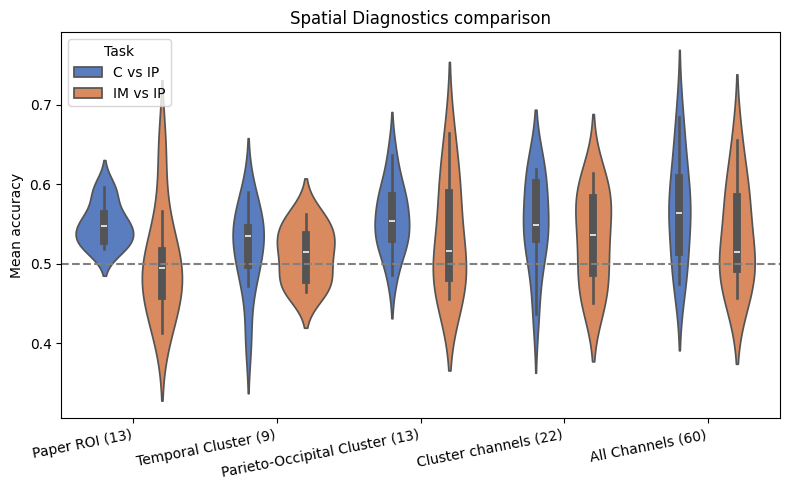


=== Temporal Diagnostics Summary ===
                       Config     Task     mean      std
     Second window (0.5-1.0s) IM vs IP 0.571176 0.048002
Conflict Window (~0.3-1.242s) IM vs IP 0.566554 0.074720
        Full Epoch (0.0-1.5s) IM vs IP 0.535271 0.065183
      First window (0.0-0.5s) IM vs IP 0.508690 0.050306
      Third window (1.0-1.5s) IM vs IP 0.507621 0.071726
Conflict Window (~0.3-1.242s)  C vs IP 0.576347 0.078903
     Second window (0.5-1.0s)  C vs IP 0.572307 0.065261
        Full Epoch (0.0-1.5s)  C vs IP 0.568376 0.066453
      Third window (1.0-1.5s)  C vs IP 0.563025 0.048115
      First window (0.0-0.5s)  C vs IP 0.480008 0.031979


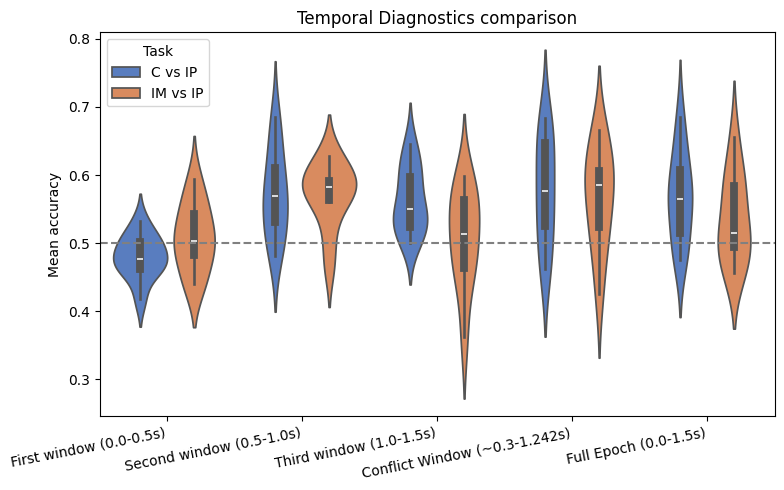


=== Spectral Diagnostics Summary ===
               Config     Task     mean      std
  Broadband (1-40 Hz) IM vs IP 0.562350 0.034283
       Theta (5-7 Hz) IM vs IP 0.518896 0.076483
Theta+Alpha (5-12 Hz) IM vs IP 0.514469 0.067511
      Alpha (8-12 Hz) IM vs IP 0.500692 0.048257
Theta+Alpha (5-12 Hz)  C vs IP 0.574311 0.059049
  Broadband (1-40 Hz)  C vs IP 0.565614 0.089113
      Alpha (8-12 Hz)  C vs IP 0.553748 0.060202
       Theta (5-7 Hz)  C vs IP 0.538075 0.031346


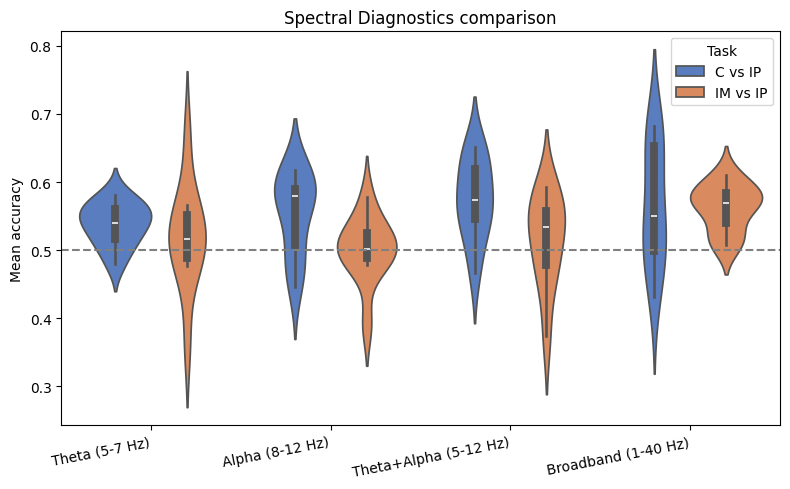

In [ ]:
from mne.filter import filter_data

cache_file = paths.cache_dir / "exp2_diagnostics.csv"
CONFLICT_WINDOWS = {"C vs IP": (0.375, 1.242), "IM vs IP": (0.258, 1.242)}

try:
    df_diag = pd.read_csv(cache_file)
    # Render comparative plots side by side
    for dim in ["Spatial", "Temporal", "Spectral"]:
        print(f"\n=== {dim} Diagnostics Summary ===")
        dim_summary = (
            df_diag[df_diag["Dimension"] == dim]
            .groupby(["Config", "Task"])["Accuracy"]
            .agg(["mean", "std"])
            .reset_index()
        )
        dim_summary = dim_summary.sort_values(["Task", "mean"], ascending=False)
        print(dim_summary.to_string(index=False))

        plt.figure(figsize=(8, 5))
        sns.violinplot(data=df_diag[df_diag["Dimension"] == dim], x="Config", y="Accuracy", hue="Task", palette="muted")
        plt.axhline(0.5, linestyle="--", color="gray")
        plt.title(f"{dim} Diagnostics comparison")
        plt.xticks(rotation=11)
        plt.xlabel("")
        plt.ylabel("Mean accuracy")
        plt.tight_layout()
        plt.savefig(paths.figures_dir / f"experiment2_{dim.lower()}_diagnostics.png", dpi=300)
        plt.show()
except FileNotFoundError:
    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    tasks_dict = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    all_diagnostics = []
    sfreq = 128.0

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        for sub in target_subjects:
            print(f"Processing diagnostics for Task: {task_lbl}, Subject: {sub}")
            X_sub, y_sub = X_dict[sub], y_dict[sub]

            # 1. Spatial Scope Ablation
            spatial_configs = {
                "Paper ROI (13)": [ch for ch in roi_chans if ch in ds.channel_names],
                "Temporal Cluster (9)": [ch for ch in TARGET_BANDS_CLUSTERS["theta"] if ch in ds.channel_names],
                "Parieto-Occipital Cluster (13)": [
                    ch for ch in TARGET_BANDS_CLUSTERS["alpha"] if ch in ds.channel_names
                ],
                "Cluster channels (22)": [ch for ch in cluster_chans if ch in ds.channel_names],
                "All Channels (60)": ds.channel_names,
            }
            for spat_name, picks in spatial_configs.items():
                picks_idx = [ds.channel_names.index(ch) for ch in picks]
                # standard Z-scoring, Riemann
                X_crop = X_sub[:, picks_idx]

                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                accs = []
                for tr, te in splits:
                    X_tr, X_te = standardize_subject_wise(X_crop[tr], X_crop[te])
                    pipeline = make_pipeline(
                        Covariances(estimator="oas"),
                        TangentSpace(metric="riemann"),
                        LDA(solver="lsqr", shrinkage="auto"),
                    )
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                all_diagnostics.append(
                    {
                        "Task": task_lbl,
                        "Dimension": "Spatial",
                        "Config": spat_name,
                        "Accuracy": np.mean(accs),
                        "Std Dev": np.std(accs),
                    }
                )

            # 2. Time Scope Ablation
            conflict_start, conflict_stop = CONFLICT_WINDOWS[task_lbl]
            time_configs = {
                "First window (0.0-0.5s)": (ds.times >= 0.0) & (ds.times <= 0.5),
                "Second window (0.5-1.0s)": (ds.times > 0.5) & (ds.times <= 1.0),
                "Third window (1.0-1.5s)": (ds.times > 1.0) & (ds.times <= 1.5),
                "Conflict Window": (ds.times >= conflict_start) & (ds.times <= conflict_stop),
                "Full Epoch (0.0-1.5s)": (ds.times >= 0.0) & (ds.times <= 1.5),
            }
            for time_name, t_mask in time_configs.items():
                X_crop = X_sub[..., t_mask]
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                accs = []
                for tr, te in splits:
                    X_tr, X_te = standardize_subject_wise(X_crop[tr], X_crop[te])
                    pipeline = make_pipeline(
                        Covariances(estimator="oas"),
                        TangentSpace(metric="riemann"),
                        LDA(solver="lsqr", shrinkage="auto"),
                    )
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                all_diagnostics.append(
                    {
                        "Task": task_lbl,
                        "Dimension": "Temporal",
                        "Config": time_name,
                        "Accuracy": np.mean(accs),
                        "Std Dev": np.std(accs),
                    }
                )

            # 3. Spectral Scope Ablation
            spectral_configs = {
                "Theta (5-7 Hz)": (5.0, 7.0),
                "Alpha (8-12 Hz)": (8.0, 12.0),
                "Theta+Alpha (5-12 Hz)": (5.0, 12.0),
                "Broadband (1-40 Hz)": (1.0, 40.0),
            }
            # Keep spectral diagnostics unchanged from the original experiment.
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
            for spec_name, (l_freq, h_freq) in spectral_configs.items():
                X_filt = filter_data(
                    X_sub[..., t_mask].astype(np.float64),
                    sfreq=sfreq,
                    l_freq=l_freq,
                    h_freq=h_freq,
                    method="iir",
                    verbose=False,
                )
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                accs = []
                for tr, te in splits:
                    X_tr, X_te = standardize_subject_wise(X_filt[tr], X_filt[te])
                    pipeline = make_pipeline(
                        Covariances(estimator="oas"),
                        TangentSpace(metric="riemann"),
                        LDA(solver="lsqr", shrinkage="auto"),
                    )
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                all_diagnostics.append(
                    {
                        "Task": task_lbl,
                        "Dimension": "Spectral",
                        "Config": spec_name,
                        "Accuracy": np.mean(accs),
                        "Std Dev": np.std(accs),
                    }
                )

    df_diag = pd.DataFrame(all_diagnostics)
    df_diag.to_csv(cache_file, index=False)

### Experiment 3: Classical Machine Learning Branch (LR, LDA, RF, XGB, LGBM)

Using fold-wise Hilbert average envelope amplitudes from the representation choices suggested by Experiments 1-2, we compare five classical models for **both** tasks. The feature recipe is task-specific but fixed before model comparison: C vs IP uses the theta+alpha conflict-window cluster because it was strongest in the previous diagnostics, while IM vs IP uses broadband features in the second window over all channels because those were strongest for that task.



=== Classical Machine Learning Comparison ===
    Task                   Classifier     mean      std  count
 C vs IP          Logistic Regression 0.566194 0.094773     50
 C vs IP Linear Discriminant Analysis 0.552381 0.089797     50
 C vs IP                      XGBoost 0.535705 0.090438     50
 C vs IP                Random Forest 0.532697 0.094762     50
 C vs IP                     LightGBM 0.512623 0.103223     50
IM vs IP          Logistic Regression 0.516120 0.088925     50
IM vs IP Linear Discriminant Analysis 0.505831 0.119269     50
IM vs IP                     LightGBM 0.503436 0.098212     50
IM vs IP                      XGBoost 0.501512 0.092444     50
IM vs IP                Random Forest 0.497605 0.103525     50


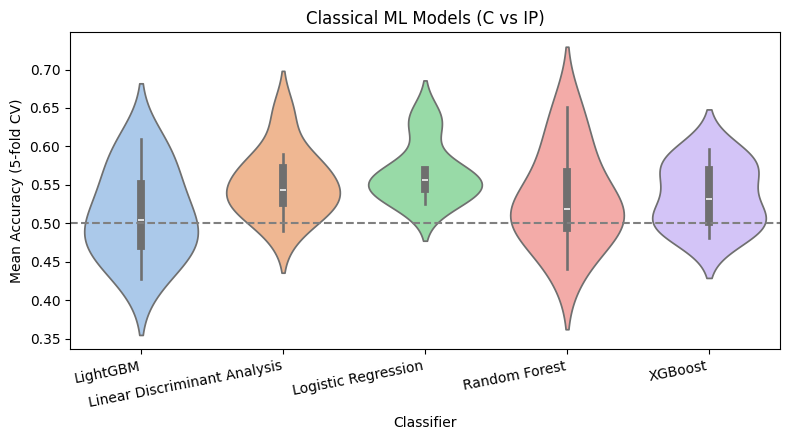

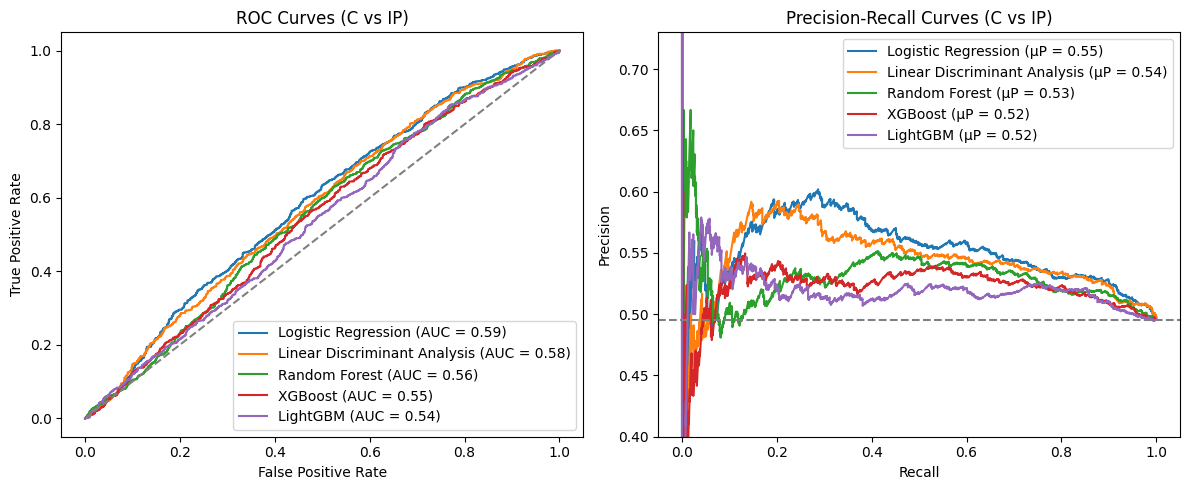

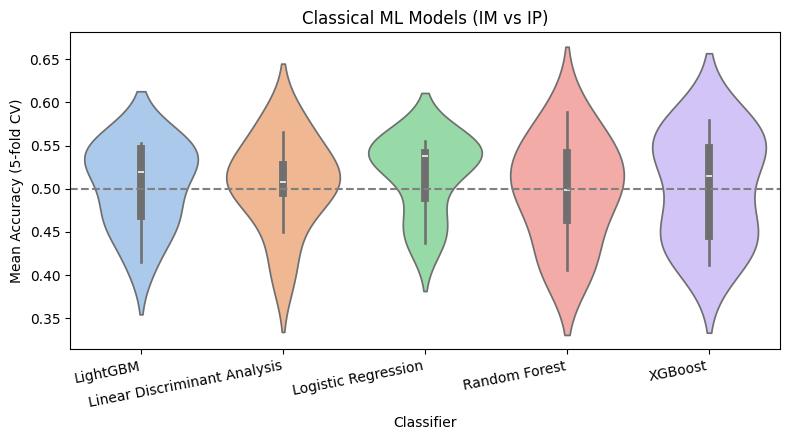

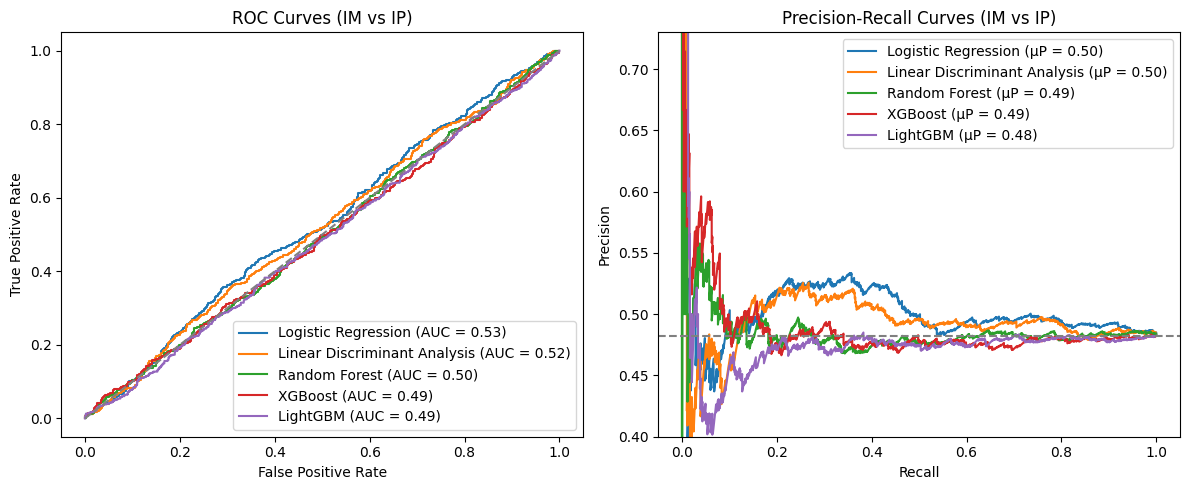

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

cache_file = paths.tables_dir / "exp3_classical_ml_results.csv"


def extract_exp3_features(X_sub, ds, *, channel_mode, time_window, bandpass):
    if channel_mode == "all":
        ch_idx = list(range(len(ds.channel_names)))
    elif channel_mode == "cluster":
        cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
        ch_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
    elif channel_mode == "parieto_occipital":
        ch_idx = [ds.channel_names.index(ch) for ch in TARGET_BANDS_CLUSTERS["alpha"] if ch in ds.channel_names]
    else:
        raise ValueError(f"Unknown channel_mode: {channel_mode}")

    t_mask = (ds.times >= time_window[0]) & (ds.times <= time_window[1])
    X_sel = X_sub[:, ch_idx, :]
    if bandpass is not None:
        X_sel = filter_data(
            X_sel.astype(np.float64),
            sfreq=128.0,
            l_freq=bandpass[0],
            h_freq=bandpass[1],
            method="iir",
            verbose=False,
        )
    envelopes = np.abs(hilbert(X_sel[..., t_mask], axis=-1))
    return envelopes.mean(axis=-1)


try:
    df_ml = pd.read_csv(cache_file)
    if "Task" not in df_ml.columns:
        df_ml["Task"] = "C vs IP"

    fold_summary = df_ml.groupby(["Task", "Classifier", "Subject", "Fold"])["Fold_Accuracy"].first().reset_index()
    summary_mean = (
        fold_summary.groupby(["Task", "Classifier"])["Fold_Accuracy"]
        .agg(["mean", "std", "count"])
        .reset_index()
        .sort_values(["Task", "mean"], ascending=[True, False])
    )

    print("\n=== Classical Machine Learning Comparison ===")
    print(summary_mean.to_string(index=False))

    for task_lbl in ["C vs IP", "IM vs IP"]:
        d_fold = fold_summary[fold_summary["Task"] == task_lbl]
        d_trials = df_ml[df_ml["Task"] == task_lbl]
        if d_fold.empty or d_trials.empty:
            continue

        plt.figure(figsize=(8, 4.5))
        df_violin = d_fold.groupby(["Classifier", "Subject"])["Fold_Accuracy"].mean().reset_index()
        sns.violinplot(data=df_violin, x="Classifier", y="Fold_Accuracy", palette="pastel", hue="Classifier")
        plt.axhline(0.5, linestyle="--", color="gray")
        plt.title(f"Classical ML Models ({task_lbl})")
        plt.ylabel("Mean Accuracy (5-fold CV)")
        plt.xticks(rotation=11)
        plt.tight_layout()
        tag = "c_vs_ip" if task_lbl == "C vs IP" else "im_vs_ip"
        plt.savefig(paths.figures_dir / f"experiment3_classical_ml_comparison_{tag}.png", dpi=300)
        plt.show()

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        for name in d_trials["Classifier"].unique():
            df_clf = d_trials[d_trials["Classifier"] == name]
            y_true = df_clf["True_Label"].values
            y_scores = df_clf["Probability"].values
            fpr, tpr, _ = roc_curve(y_true, y_scores)
            precision, recall, _ = precision_recall_curve(y_true, y_scores)
            axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.2f})")
            axes[1].plot(recall, precision, label=f"{name} (μP = {average_precision_score(y_true, y_scores):.2f})")

        axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
        axes[0].set_title(f"ROC Curves ({task_lbl})")
        axes[0].set_xlabel("False Positive Rate")
        axes[0].set_ylabel("True Positive Rate")
        axes[0].legend()

        axes[1].axhline(d_trials["True_Label"].mean(), linestyle="--", color="gray")
        axes[1].set_title(f"Precision-Recall Curves ({task_lbl})")
        axes[1].set_xlabel("Recall")
        axes[1].set_ylabel("Precision")
        axes[1].set_ylim([0.4, 0.73])
        axes[1].legend()

        plt.tight_layout()
        plt.savefig(paths.figures_dir / f"experiment3_classical_ml_roc_pr_curves_{tag}.png", dpi=300)
        plt.show()

except FileNotFoundError:
    model_factories = {
        "Logistic Regression": lambda: LogisticRegression(
            C=1.0, penalty="l2", class_weight="balanced", random_state=42
        ),
        "Linear Discriminant Analysis": lambda: LDA(solver="lsqr", shrinkage="auto"),
        "Random Forest": lambda: RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
        "XGBoost": lambda: XGBClassifier(
            n_estimators=50, max_depth=3, learning_rate=0.1, random_state=42, eval_metric="logloss"
        ),
        "LightGBM": lambda: LGBMClassifier(
            n_estimators=50, max_depth=3, learning_rate=0.1, random_state=42, verbose=-1
        ),
    }

    task_feature_configs = {
        "C vs IP": {
            "data": (X_subs_c, y_subs_c, dataset_c),
            "channel_mode": "cluster",
            "time_window": (0.375, 1.242),
            "bandpass": (5.0, 12.0),
            "feature_label": "Cluster theta+alpha envelope, conflict window",
        },
        "IM vs IP": {
            "data": (X_subs_im, y_subs_im, dataset_im),
            "channel_mode": "all",
            "time_window": (0.5, 1.0),
            "bandpass": (1.0, 40.0),
            "feature_label": "All-channel broadband envelope, second window",
        },
    }

    ml_results = []

    for task_lbl, cfg in task_feature_configs.items():
        X_dict, y_dict, ds = cfg["data"]
        print(f"\nRunning Experiment 3 model comparison for {task_lbl}: {cfg['feature_label']}")
        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            X_feats = extract_exp3_features(
                X_sub,
                ds,
                channel_mode=cfg["channel_mode"],
                time_window=cfg["time_window"],
                bandpass=cfg["bandpass"],
            )
            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

            for name, make_clf in model_factories.items():
                for fold_idx, (tr, te) in enumerate(splits, start=1):
                    clf = make_clf()
                    pipeline = make_pipeline(StandardScaler(), clf)
                    pipeline.fit(X_feats[tr], y_sub[tr])
                    y_true = y_sub[te]
                    y_pred = pipeline.predict(X_feats[te])
                    if hasattr(pipeline, "predict_proba"):
                        y_probs = pipeline.predict_proba(X_feats[te])[:, 1]
                    else:
                        scores = pipeline.decision_function(X_feats[te])
                        y_probs = 1.0 / (1.0 + np.exp(-scores))
                    acc = accuracy_score(y_true, y_pred)

                    for idx in range(len(y_true)):
                        ml_results.append(
                            {
                                "Task": task_lbl,
                                "Subject": sub,
                                "Classifier": name,
                                "Fold": fold_idx,
                                "True_Label": int(y_true[idx]),
                                "Probability": float(y_probs[idx]),
                                "Fold_Accuracy": acc,
                                "Feature_Set": cfg["feature_label"],
                            }
                        )

    df_ml = pd.DataFrame(ml_results)
    df_ml.to_csv(cache_file, index=False)

### Experiment 4: Classical Spatial Baselines (CSP, FBCSP, Riemann)

Spatial filter baselines learn combinations of signals that optimize condition variance. We compare:
1. **Broadband CSP + LDA**
2. **Filter Bank CSP (FBCSP) + LDA** (extracting spatial filters in parallel over Theta, Alpha, and Beta)
3. **Riemannian Covariance**: oasis-estimation covariance matrices projected onto Tangent space and classified by shrinkage LDA.


=== Spatial Baselines comparison (C vs IP) ===
                   Model  Accuracy
Riemann Covariance + LDA  0.576778
             FBCSP + LDA  0.564694
     Broadband CSP + LDA  0.560416


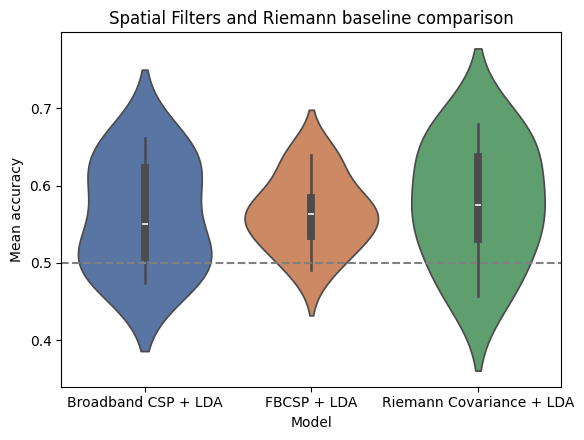

In [ ]:
from mne.decoding import CSP

cache_file = paths.tables_dir / "exp4_spatial_baselines.csv"

try:
    df_spat = pd.read_csv(cache_file)
    summary = df_spat.groupby("Model")["Accuracy"].mean().reset_index().sort_values("Accuracy", ascending=False)
    print("\n=== Spatial Baselines comparison (C vs IP) ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(6, 4.5))
    sns.violinplot(data=df_spat, x="Model", y="Accuracy", palette="deep", hue="Model")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Spatial Filters and Riemann baseline comparison")
    plt.ylabel("Mean accuracy")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment4_spatial_baselines_comparison.png", dpi=300)
    plt.show()
except FileNotFoundError:
    spatial_results = []

    for sub in target_subjects:
        X_sub, y_sub = X_subs_c[sub], y_subs_c[sub]
        t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
        X_crop = X_sub[..., t_mask] * 1e6

        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

        # 1. Broadband CSP
        accs_csp = []
        for tr, te in splits:
            csp = CSP(n_components=4, reg="ledoit_wolf", log=True, cov_est="epoch")
            clf = LDA(solver="lsqr", shrinkage="auto")
            X_tr = csp.fit_transform(X_crop[tr].astype(np.float64), y_sub[tr])
            X_te = csp.transform(X_crop[te].astype(np.float64))
            clf.fit(X_tr, y_sub[tr])
            accs_csp.append(accuracy_score(y_sub[te], clf.predict(X_te)))
        spatial_results.append({"Subject": sub, "Model": "Broadband CSP + LDA", "Accuracy": np.mean(accs_csp)})

        # 2. Filter Bank CSP (Theta, Alpha, Beta)
        fbands = {"Theta": (4.0, 8.0), "Alpha": (8.0, 12.0), "Beta": (12.0, 30.0)}
        X_filt_bands = {}
        for bname, (lf, hf) in fbands.items():
            X_filt_bands[bname] = filter_data(
                X_crop.astype(np.float64), sfreq=128.0, l_freq=lf, h_freq=hf, method="iir", verbose=False
            )

        accs_fbcsp = []
        for tr, te in splits:
            tr_feats, te_feats = [], []
            for bname in fbands:
                csp = CSP(n_components=4, reg="ledoit_wolf", log=True, cov_est="epoch")
                tr_feats.append(csp.fit_transform(X_filt_bands[bname][tr], y_sub[tr]))
                te_feats.append(csp.transform(X_filt_bands[bname][te]))
            X_tr_fb = np.concatenate(tr_feats, axis=1)
            X_te_fb = np.concatenate(te_feats, axis=1)
            clf = LDA(solver="lsqr", shrinkage="auto")
            clf.fit(X_tr_fb, y_sub[tr])
            accs_fbcsp.append(accuracy_score(y_sub[te], clf.predict(X_te_fb)))
        spatial_results.append({"Subject": sub, "Model": "FBCSP + LDA", "Accuracy": np.mean(accs_fbcsp)})

        # 3. Riemann Baseline
        accs_riemann = []
        for tr, te in splits:
            pipeline = make_pipeline(
                Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
            )
            pipeline.fit(X_crop[tr], y_sub[tr])
            accs_riemann.append(accuracy_score(y_sub[te], pipeline.predict(X_crop[te])))
        spatial_results.append({"Subject": sub, "Model": "Riemann Covariance + LDA", "Accuracy": np.mean(accs_riemann)})

    df_spat = pd.DataFrame(spatial_results)
    df_spat.to_csv(cache_file, index=False)

### Experiment 5: Connectivity & Network Structure Representations

Because Binocular Rivalry is hypothesized to involve frontomedial and parieto-occipital interactions, we calculate **trial-wise Phase Locking Value (PLV)** connectivity matrices in the Theta and Alpha bands for both tasks. PLV matrices are treated as connectivity features rather than covariance matrices: we vectorize the upper triangle, standardize features inside each training fold, and classify with LDA. Results are stored at fold level and summarized with text-only tests against chance.



=== Connectivity Classification Results ===
    Task Connectivity     mean      std  count
 C vs IP    Alpha PLV 0.503705 0.046581     10
 C vs IP    Theta PLV 0.511866 0.049336     10
IM vs IP    Alpha PLV 0.503015 0.039232     10
IM vs IP    Theta PLV 0.472513 0.054607     10

=== Text-only statistical tests vs chance (0.5) ===
C vs IP | Alpha PLV: mean=0.504, sd=0.047, n_folds=10, one-sample t-test p=0.4035, Wilcoxon p=0.3477
C vs IP | Theta PLV: mean=0.512, sd=0.049, n_folds=10, one-sample t-test p=0.2332, Wilcoxon p=0.3125
IM vs IP | Alpha PLV: mean=0.503, sd=0.039, n_folds=10, one-sample t-test p=0.4067, Wilcoxon p=0.4229
IM vs IP | Theta PLV: mean=0.473, sd=0.055, n_folds=10, one-sample t-test p=0.9270, Wilcoxon p=0.9199


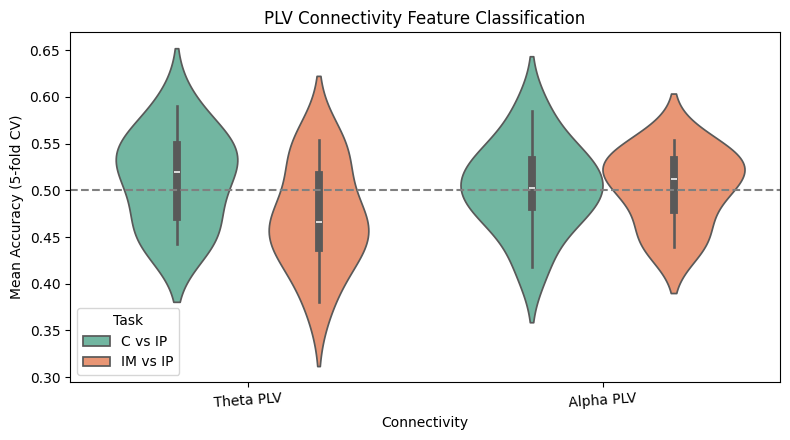

In [ ]:
def compute_trial_wise_plv(X_epoch):
    # X_epoch shape: (trials, channels, times)
    z = hilbert(X_epoch, axis=-1)
    phase = np.angle(z)
    exp_phase = np.exp(1j * phase)
    times = X_epoch.shape[-1]
    plv = np.abs(np.matmul(exp_phase, exp_phase.conj().transpose(0, 2, 1))) / times
    return plv


def vectorize_connectivity_upper_triangle(plv_tensors):
    tri = np.triu_indices(plv_tensors.shape[-1], k=1)
    return plv_tensors[:, tri[0], tri[1]].astype(np.float64)


def print_chance_test_summary(df, *, value_col="Accuracy", group_cols=("Task", "Connectivity")):
    from scipy.stats import ttest_1samp, wilcoxon

    print("\n=== Text-only statistical tests vs chance (0.5) ===")
    for keys, d in df.groupby(list(group_cols)):
        vals = d[value_col].dropna().to_numpy(dtype=float)
        if vals.size == 0:
            continue
        t_stat, t_p = ttest_1samp(vals, 0.5, alternative="greater")
        try:
            w_stat, w_p = wilcoxon(vals - 0.5, alternative="greater", zero_method="wilcox")
        except ValueError:
            w_stat, w_p = np.nan, np.nan
        key_txt = " | ".join(map(str, keys if isinstance(keys, tuple) else (keys,)))
        print(
            f"{key_txt}: mean={vals.mean():.3f}, sd={vals.std(ddof=1):.3f}, "
            f"n_folds={vals.size}, one-sample t-test p={t_p:.4f}, Wilcoxon p={w_p:.4f}"
        )


cache_file = paths.tables_dir / "exp5_connectivity_results.csv"

try:
    df_conn = pd.read_csv(cache_file)
    summary = df_conn.groupby(["Task", "Connectivity"])["Accuracy"].agg(["mean", "std", "count"]).reset_index()
    print("\n=== Connectivity Classification Results ===")
    print(summary.to_string(index=False))
    print_chance_test_summary(df_conn)

    plt.figure(figsize=(8, 4.5))
    sns.violinplot(data=df_conn, x="Connectivity", y="Accuracy", palette="Set2", hue="Task", inner="box")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("PLV Connectivity Feature Classification")
    plt.ylabel("Mean Accuracy (5-fold CV)")
    plt.xticks(rotation=4)
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment5_connectivity_comparison.png", dpi=300)
    plt.show()
except FileNotFoundError:
    conn_results = []

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        print(f"\nComputing upper-triangle PLV connectivity features for: {task_lbl}")

        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            ch_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
            X_conn = X_sub[:, ch_idx, :]

            # Filter the full epoch before Hilbert/PLV to avoid crop-edge artifacts.
            X_theta = filter_data(
                X_conn.astype(np.float64), sfreq=128.0, l_freq=5.0, h_freq=7.0, method="iir", verbose=False
            )
            X_alpha = filter_data(
                X_conn.astype(np.float64), sfreq=128.0, l_freq=8.0, h_freq=12.0, method="iir", verbose=False
            )
            features_by_band = {
                "Theta PLV upper-triangle": vectorize_connectivity_upper_triangle(compute_trial_wise_plv(X_theta)),
                "Alpha PLV upper-triangle": vectorize_connectivity_upper_triangle(compute_trial_wise_plv(X_alpha)),
            }

            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

            for name, X_feats in features_by_band.items():
                for fold_idx, (tr, te) in enumerate(splits, start=1):
                    pipeline = make_pipeline(StandardScaler(), LDA(solver="lsqr", shrinkage="auto"))
                    pipeline.fit(X_feats[tr], y_sub[tr])
                    y_pred = pipeline.predict(X_feats[te])
                    acc = accuracy_score(y_sub[te], y_pred)
                    conn_results.append(
                        {
                            "Task": task_lbl,
                            "Subject": sub,
                            "Connectivity": name,
                            "Fold": fold_idx,
                            "Accuracy": acc,
                        }
                    )

    df_conn = pd.DataFrame(conn_results)
    df_conn.to_csv(cache_file, index=False)

### Experiment 6: Focused Deep Learning Branch

1. **EEGNet representation ablation**: We keep a compact, deterministic ablation over channel scope, time crop, and normalization so the result remains interpretable and reproducible.
2. **ST-GNN topology ablation**: Optuna is intentionally not used here. The scientific question is which graph prior is more robust, so we compare fixed topologies under the same training budget: physical electrode distance, train-fold functional PLV, identity/no-edge control, and a dense mean-field graph. The functional graph is fit only on each training fold to avoid temporal leakage.



=== Experiment 6 Deep Learning Summary ===
    Task Family                               Variant     mean      std
 C vs IP EEGNet EEGNet | all channels conflict window 0.526530 0.068677
 C vs IP EEGNet    EEGNet | clustered conflict window 0.533571 0.073856
 C vs IP EEGNet         EEGNet | clustered full epoch 0.566225 0.060712
 C vs IP EEGNet   EEGNet | clustered no normalization 0.533986 0.081345
 C vs IP ST-GNN          ST-GNN | dense graph control 0.532791 0.071557
 C vs IP ST-GNN               ST-GNN | distance graph 0.508338 0.103252
 C vs IP ST-GNN       ST-GNN | identity graph control 0.517665 0.092306
 C vs IP ST-GNN         ST-GNN | train-fold PLV graph 0.527573 0.096543
IM vs IP EEGNet EEGNet | all channels conflict window 0.528112 0.075354
IM vs IP EEGNet    EEGNet | clustered conflict window 0.515738 0.057214
IM vs IP EEGNet         EEGNet | clustered full epoch 0.503086 0.055939
IM vs IP EEGNet   EEGNet | clustered no normalization 0.533620 0.053310
IM vs IP ST-GNN     

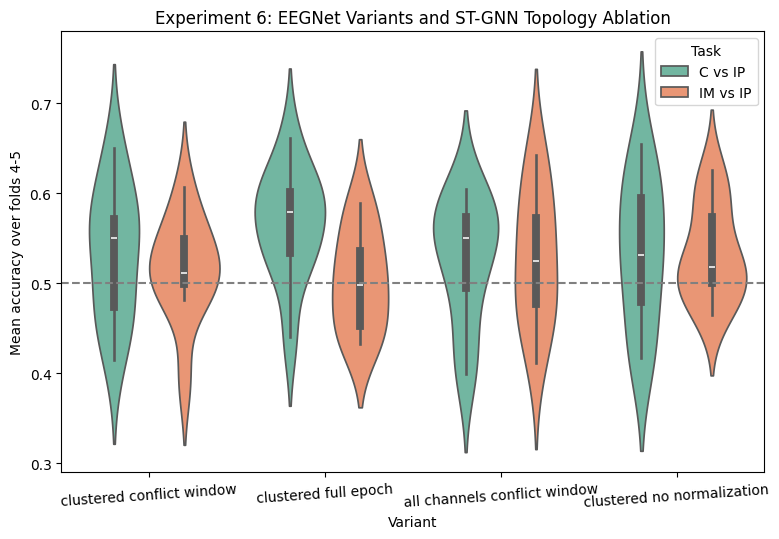

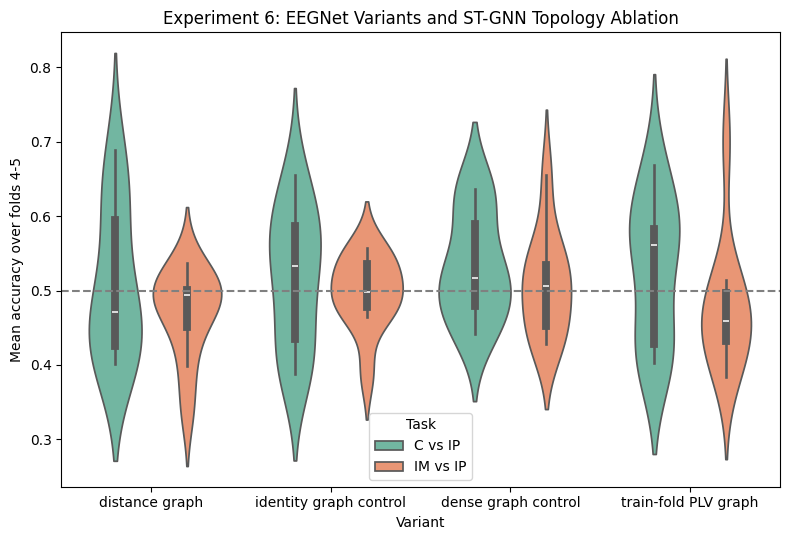

In [ ]:
cache_file = paths.tables_dir / "exp6_deep_learning_results.csv"

try:
    df_dl = pd.read_csv(cache_file)
    summary = df_dl.groupby(["Task", "Family", "Variant"])["Accuracy"].agg(["mean", "std"]).reset_index()
    df_dl_eegnet = df_dl[df_dl["Family"] == "EEGNet"].copy()
    df_dl_eegnet["Variant"] = df_dl_eegnet["Variant"].str.replace("EEGNet | ", "")
    df_dl_stgnn = df_dl[df_dl["Family"] == "ST-GNN"].copy()
    df_dl_stgnn["Variant"] = df_dl_stgnn["Variant"].str.replace("ST-GNN | ", "")
    print("\n=== Experiment 6 Deep Learning Summary ===")
    print(summary.to_string(index=False))

    # EEGNet variants violin plot
    plt.figure(figsize=(8, 5.5))
    sns.violinplot(data=df_dl_eegnet, x="Variant", y="Accuracy", hue="Task", palette="Set2")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Experiment 6: EEGNet Variants and ST-GNN Topology Ablation")
    plt.ylabel("Mean accuracy over folds 4-5")
    plt.xticks(rotation=4)
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment6_eegnet_variants_comparison.png", dpi=300)
    plt.show()

    # ST-GNN topology violin plot
    plt.figure(figsize=(8, 5.5))
    sns.violinplot(data=df_dl_stgnn, x="Variant", y="Accuracy", hue="Task", palette="Set2")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Experiment 6: EEGNet Variants and ST-GNN Topology Ablation")
    plt.ylabel("Mean accuracy over folds 4-5")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment6_stgnn_topology_comparison.png", dpi=300)
    plt.show()
except FileNotFoundError:
    import torch
    import torch.nn as nn
    from mne.filter import filter_data
    from br_analysis.torch_training import build_dataloader, _evaluate
    from br_analysis.torch_models import EEGNet, STGNNChebConv
    import seaborn as sns

    print("Stage 6: Focused Deep Learning Ablation and ST-GNN Graph Topologies")
    print("  -> EEGNet ablation: cluster/window/channel/normalization variants.")
    print("  -> ST-GNN topology ablation: fixed graph priors, no Optuna, train-fold PLV for functional graphs.")

    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
    graph_bands = {"theta": (5.0, 7.0), "alpha": (8.0, 12.0)}

    tasks_dict = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    def standardize_graph_train_test(X_train, X_test):
        mean = X_train.mean(axis=(0, 1), keepdims=True)
        std = np.maximum(X_train.std(axis=(0, 1), keepdims=True), 1e-6)
        return ((X_train - mean) / std).astype(np.float32), ((X_test - mean) / std).astype(np.float32)

    def train_eval_torch(model, X_tr, y_tr, X_te, y_te, *, epochs=5, batch_size=16, lr=1e-3, weight_decay=1e-4):
        train_loader = build_dataloader(X_tr, y_tr, batch_size=batch_size, shuffle=True, device=DEVICE)
        val_loader = build_dataloader(X_te, y_te, batch_size=batch_size, shuffle=False, device=DEVICE)
        model = model.to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        criterion = nn.CrossEntropyLoss()
        for _ in range(epochs):
            model.train()
            for bx, by in train_loader:
                bx, by = bx.to(DEVICE), by.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(bx), by)
                loss.backward()
                optimizer.step()
        _, val_acc, _, _ = _evaluate(model, val_loader, DEVICE)
        return float(val_acc)

    def mean_plv_adjacency(X_train_raw, *, sfreq, top_k=6):
        X_filt = filter_data(
            X_train_raw.astype(np.float64), sfreq=sfreq, l_freq=5.0, h_freq=12.0, method="iir", verbose=False
        )
        adj = compute_trial_wise_plv(X_filt).mean(axis=0).astype(np.float32)
        adj = (adj + adj.T) / 2.0
        np.fill_diagonal(adj, 0.0)
        keep = np.zeros_like(adj, dtype=bool)
        for row in range(adj.shape[0]):
            nn_idx = np.argsort(adj[row])[-top_k:]
            keep[row, nn_idx] = True
        keep = keep | keep.T
        adj = np.where(keep, adj, 0.0)
        np.fill_diagonal(adj, 1.0)
        return adj.astype(np.float32)

    def dense_mean_field_adjacency(n_nodes):
        adj = np.ones((n_nodes, n_nodes), dtype=np.float32)
        return adj / np.maximum(adj.sum(axis=1, keepdims=True), 1e-6)

    dl_results = []

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        print(f"\nRunning deep-learning variants for: {task_lbl}")
        distance_adj = electrode_distance_adjacency(ds.channel_names, threshold=0.35)
        identity_adj = np.eye(len(ds.channel_names), dtype=np.float32)
        dense_adj = dense_mean_field_adjacency(len(ds.channel_names))

        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
            eval_splits = splits[-2:]

            picks_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
            eegnet_variants = {
                "EEGNet | clustered conflict window": (X_sub[:, picks_idx][..., t_mask], True),
                "EEGNet | clustered full epoch": (X_sub[:, picks_idx], True),
                "EEGNet | all channels conflict window": (X_sub[..., t_mask], True),
                "EEGNet | clustered no normalization": (X_sub[:, picks_idx][..., t_mask], False),
            }

            for var_name, (X_var, use_norm) in eegnet_variants.items():
                accs = []
                for train_idx, test_idx in eval_splits:
                    X_tr, X_te = X_var[train_idx], X_var[test_idx]
                    if use_norm:
                        X_tr, X_te = standardize_subject_wise(X_tr, X_te)
                    accs.append(
                        train_eval_torch(
                            EEGNet(n_channels=X_tr.shape[1], n_times=X_tr.shape[2], n_classes=2),
                            X_tr,
                            y_sub[train_idx],
                            X_te,
                            y_sub[test_idx],
                        )
                    )
                dl_results.append(
                    {
                        "Subject": sub,
                        "Family": "EEGNet",
                        "Variant": var_name,
                        "Accuracy": np.mean(accs),
                        "Task": task_lbl,
                    }
                )

            X_graph, _, _ = temporal_band_features(
                X_sub,
                128.0,
                bands=graph_bands,
                window_sec=0.500,
                step_sec=0.100,
                mode="de",
            )
            stgnn_static_variants = {
                "ST-GNN | distance graph": distance_adj,
                "ST-GNN | identity graph control": identity_adj,
                "ST-GNN | dense graph control": dense_adj,
            }

            for var_name in [*stgnn_static_variants.keys(), "ST-GNN | train-fold PLV graph"]:
                accs = []
                for train_idx, test_idx in eval_splits:
                    X_tr, X_te = standardize_graph_train_test(X_graph[train_idx], X_graph[test_idx])
                    if var_name == "ST-GNN | train-fold PLV graph":
                        adjacency = mean_plv_adjacency(X_sub[train_idx], sfreq=128.0, top_k=6)
                    else:
                        adjacency = stgnn_static_variants[var_name]
                    model = STGNNChebConv(
                        n_nodes=X_tr.shape[2],
                        in_features=X_tr.shape[3],
                        adjacency=adjacency,
                        n_classes=2,
                        cheb_hidden=24,
                        temporal_hidden=48,
                        K=3,
                        dropout=0.35,
                    )
                    accs.append(
                        train_eval_torch(model, X_tr, y_sub[train_idx], X_te, y_sub[test_idx], epochs=6, batch_size=32)
                    )
                dl_results.append(
                    {
                        "Subject": sub,
                        "Family": "ST-GNN",
                        "Variant": var_name,
                        "Accuracy": np.mean(accs),
                        "Task": task_lbl,
                    }
                )

    df_dl = pd.DataFrame(dl_results)
    df_dl.to_csv(cache_file, index=False)

### Experiment 7: Pretrained Models & Transfer Learning

Using the pre-trained foundation model Large Brain Model (LaBraM), we evaluate downstream adaptation strategies:
1. **Linear Probe**: Freeze all backbone weights and train only the classification head.
2. **LoRA Fine-Tuning**: Inject low-rank adapters into self-attention blocks and MLP layers. We tune rank, dropout, and weight decay.

In [ ]:
cache_file = paths.tables_dir / "exp7_pretrained_models_results.csv"

try:
    raise FileNotFoundError  # Force re-run of transfer learning stage for updated LoRA implementation
    df_tf = pd.read_csv(cache_file)
    summary = df_tf.groupby(["Task", "Strategy"])["Accuracy"].mean().reset_index()
    print("\n=== Transfer Learning Summary ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(8, 4.5))
    sns.violinplot(data=df_tf, x="Strategy", y="Accuracy", hue="Strategy", palette="Accent")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("LaBraM Transfer Learning Performance")
    plt.ylabel("Accuracy")
    plt.xlabel("")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / f"experiment7_labram_transfer_comparison.png", dpi=300)
    plt.show()
except FileNotFoundError:
    import os
    import torch
    import torch.nn as nn
    from huggingface_hub import hf_hub_download
    from braindecode.models import InterpolatedLaBraM
    from br_analysis.torch_training import build_dataloader, _evaluate
    from br_analysis.pretrained import prepare_lora_backbone, load_backbone_weights
    import seaborn as sns

    print("Stage 7: Foundation Models Transfer Learning")
    print("  -> Real pretrained LaBraM from HuggingFace: braindecode/labram-pretrained")
    print("  -> Linear Probe vs. LoRA parameter adaptation")

    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
    TARGET_LEN = 200

    tasks_dict = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    def get_labram_checkpoint():
        checkpoint_path = None
        if os.path.exists("/kaggle/input"):
            for root, _, files in os.walk("/kaggle/input"):
                if "model.safetensors" in files and "labram" in root.lower():
                    checkpoint_path = Path(root) / "model.safetensors"
                    break
        if checkpoint_path is None:
            checkpoint_path = hf_hub_download(
                repo_id="braindecode/labram-pretrained",
                filename="model.safetensors",
            )
        return Path(checkpoint_path)

    labram_checkpoint = get_labram_checkpoint()
    print(f"Using LaBraM checkpoint: {labram_checkpoint}")

    def pad_or_crop_to_target_len(X, target_len=TARGET_LEN):
        if X.shape[-1] == target_len:
            return X
        if X.shape[-1] > target_len:
            return X[..., :target_len]
        pad_width = target_len - X.shape[-1]
        return np.pad(X, ((0, 0), (0, 0), (0, pad_width)), mode="edge")

    def unfreeze_labram_classifier(model):
        unfrozen = 0
        if hasattr(model, "get_classifier"):
            classifier = model.get_classifier()
            for param in classifier.parameters():
                param.requires_grad = True
                unfrozen += param.numel()
        for name, param in model.named_parameters():
            if any(key in name.lower() for key in ("head", "classifier", "final", "out_proj", "output")):
                param.requires_grad = True
                unfrozen += param.numel()
        return unfrozen

    def trainable_parameters_or_raise(model, *, context):
        params = [p for p in model.parameters() if p.requires_grad]
        if not params:
            head_params = unfreeze_labram_classifier(model)
            params = [p for p in model.parameters() if p.requires_grad]
        if not params:
            sample_names = [name for name, _ in list(model.named_parameters())[:20]]
            raise RuntimeError(
                f"No trainable parameters for {context}. " f"Available first parameter names: {sample_names}"
            )
        return params

    def make_real_labram(channel_names, n_outputs=2):
        ch_names = list(channel_names)
        info = mne.create_info(ch_names=ch_names, sfreq=128.0, ch_types="eeg")
        montage = mne.channels.make_standard_montage("standard_1005")
        info.set_montage(montage, on_missing="ignore")
        model = InterpolatedLaBraM(
            chs_info=info["chs"],
            n_times=TARGET_LEN,
            n_outputs=n_outputs,
            patch_size=200,
        )
        load_backbone_weights(model, labram_checkpoint, strict=False)
        return model

    transfer_results = []

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        print(f"\nRunning real LaBraM downstream transfer for: {task_lbl}")
        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            picks_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
            # Keep the original Stage-7 cluster/window comparison setup; LaBraM input is padded to pretrained length.
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
            X_crop = pad_or_crop_to_target_len(X_sub[:, picks_idx][..., t_mask])

            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
            for strategy in ["Linear Probe", "LoRA (r=2)", "LoRA (r=8)"]:
                for fold_idx, (train_idx, test_idx) in enumerate(splits[-2:], start=4):
                    X_tr, X_te = X_crop[train_idx], X_crop[test_idx]
                    y_tr, y_te = y_sub[train_idx], y_sub[test_idx]
                    X_tr, X_te = standardize_subject_wise(X_tr, X_te)

                    train_loader = build_dataloader(X_tr, y_tr, batch_size=8, shuffle=True, device=DEVICE)
                    val_loader = build_dataloader(X_te, y_te, batch_size=8, shuffle=False, device=DEVICE)

                    selected_channel_names = [ds.channel_names[i] for i in picks_idx]
                    backbone = make_real_labram(selected_channel_names, n_outputs=2)

                    if strategy == "Linear Probe":
                        for param in backbone.parameters():
                            param.requires_grad = False
                        unfreeze_labram_classifier(backbone)
                    elif strategy == "LoRA (r=2)":
                        prepare_lora_backbone(
                            backbone,
                            include_substrings=("attn", "mlp"),
                            exclude_substrings=("head", "classifier", "interpolation_layer"),
                            r=2,
                            alpha=4.0,
                            dropout=0.2,
                            train_classifier=True,
                        )
                    else:
                        prepare_lora_backbone(
                            backbone,
                            include_substrings=("attn", "mlp"),
                            exclude_substrings=("head", "classifier", "interpolation_layer"),
                            r=8,
                            alpha=16.0,
                            dropout=0.05,
                            train_classifier=True,
                        )

                    unfreeze_labram_classifier(backbone)
                    model = backbone.to(DEVICE)
                    optimizer = torch.optim.AdamW(
                        trainable_parameters_or_raise(model, context=f"LaBraM {strategy}"),
                        lr=3e-5,
                        weight_decay=1e-2 if strategy != "LoRA (r=8)" else 1e-4,
                    )
                    criterion = nn.CrossEntropyLoss()

                    for epoch in range(5):
                        model.train()
                        for bx, by in train_loader:
                            bx, by = bx.to(DEVICE), by.to(DEVICE)
                            optimizer.zero_grad(set_to_none=True)
                            out = model(bx)
                            loss = criterion(out, by)
                            loss.backward()
                            optimizer.step()

                    _, val_acc, _, _ = _evaluate(model, val_loader, DEVICE)
                    transfer_results.append(
                        {
                            "Subject": sub,
                            "Strategy": strategy,
                            "Fold": fold_idx,
                            "Accuracy": val_acc,
                            "Task": task_lbl,
                            "Backbone": "braindecode/labram-pretrained",
                            "Checkpoint": str(labram_checkpoint),
                        }
                    )

    df_tf = pd.DataFrame(transfer_results)
    df_tf.to_csv(cache_file, index=False)

Stage 7: Foundation Models Transfer Learning
  -> Real pretrained LaBraM from HuggingFace: braindecode/labram-pretrained
  -> Linear Probe vs. LoRA parameter adaptation
Using LaBraM checkpoint: C:\Users\nils\.cache\huggingface\hub\models--braindecode--labram-pretrained\snapshots\0563b6c626e7b40d9a36653b763715db94d945d7\model.safetensors

Running real LaBraM downstream transfer for: C vs IP


KeyboardInterrupt: 

### Experiment 8: Joint Space Hyperparameter Optimization (Optuna Joint Search)

To address parameter interactions (where choices like preprocessing, spatial selection, frequency band, and classifier are coupled and cannot be optimized strictly sequentially), we implement a joint hyperparameter search. We define a discrete parameter space spanning preprocessing normalizations (None, StandardScaler, RobustScaler, and Trial-wise Z-scoring), spatial scope configurations, spectral band configurations, and standard classifiers (Riemannian and Classical ML). This search optimizes validation accuracy on Fold 5 (training on Folds 1-4) across target subjects using Optuna.


In [ ]:
cache_file = paths.tables_dir / "exp8_optuna_results.csv"

try:
    df_opt = pd.read_csv(cache_file)
    print("Loaded cached results for Experiment 8.")

    summary = df_opt.groupby("Model Family")["Accuracy"].agg(["mean", "std"]).reset_index()
    print("\n=== Optuna Hyperparameter Optimization Summary (C vs IP) ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df_opt, x="Model Family", y="Accuracy", palette="Set2", hue="Model Family", showfliers=False)
    sns.stripplot(data=df_opt, x="Model Family", y="Accuracy", color="black", alpha=0.6, jitter=0.2, size=6)
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Joint Hyperparameter Optimization on Fold 5 (Experiment 8)")
    plt.ylabel("Validation Accuracy")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment8_optuna_hyperparameter_comparison.png", dpi=300)
    plt.show()
except FileNotFoundError:
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    from sklearn.pipeline import make_pipeline
    from pyriemann.estimation import Covariances
    from pyriemann.tangentspace import TangentSpace
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler, RobustScaler
    from sklearn.metrics import accuracy_score
    from mne.filter import filter_data
    from scipy.signal import welch
    import warnings

    warnings.filterwarnings("ignore")

    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    optuna_results = []

    for sub in target_subjects:
        X_sub, y_sub = X_subs_c[sub], y_subs_c[sub]
        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
        tr_idx, val_idx = splits[-1][0], splits[-1][1]

        def objective(trial):
            # 1. Preprocessing Norm
            norm = trial.suggest_categorical("norm", ["zscore", "trial_zscore", "none"])

            # 2. Spatial Scope Picks
            spatial = trial.suggest_categorical("spatial", ["ROI", "Cluster", "All"])
            if spatial == "ROI":
                picks = [ch for ch in roi_chans if ch in dataset_c.channel_names]
            elif spatial == "Cluster":
                picks = [ch for ch in cluster_chans if ch in dataset_c.channel_names]
            else:
                picks = dataset_c.channel_names
            picks_idx = [dataset_c.channel_names.index(ch) for ch in picks]

            # 3. Spectral Scope Band
            band = trial.suggest_categorical("band", ["Theta", "Alpha", "Broadband"])
            if band == "Theta":
                lf, hf = 5.0, 7.0
            elif band == "Alpha":
                lf, hf = 8.0, 12.0
            else:
                lf, hf = 1.0, 40.0

            # 4. Time Scope crop
            time_scope = trial.suggest_categorical("time_scope", ["conflict", "full", "0-0.5s", "0.5-1s", "1-1.5s"])
            if time_scope == "conflict":
                t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
            elif time_scope == "0-0.5s":
                t_mask = (dataset_c.times >= 0.0) & (dataset_c.times <= 0.5)
            elif time_scope == "0.5-1s":
                t_mask = (dataset_c.times >= 0.5) & (dataset_c.times <= 1.0)
            elif time_scope == "1-1.5s":
                t_mask = (dataset_c.times >= 1.0) & (dataset_c.times <= 1.5)
            else:
                t_mask = (dataset_c.times >= 0.0) & (dataset_c.times <= 1.5)

            X_crop = X_sub[:, picks_idx][..., t_mask]
            X_filt = filter_data(
                X_crop.astype(np.float64), sfreq=128.0, l_freq=lf, h_freq=hf, method="iir", verbose=False
            )

            # 5. Model Family
            model_family = trial.suggest_categorical("model_family", ["Riemann", "Classical ML"])

            if model_family == "Riemann":
                cov_est = trial.suggest_categorical("riemann_cov", ["oas", "lwf", "cov"])
                X_tr, X_val = X_filt[tr_idx], X_filt[val_idx]

                if norm == "zscore":
                    X_tr, X_val = standardize_standard_scaler(X_tr, X_val)
                elif norm == "trial_zscore":
                    X_tr, X_val = standardize_trial_wise(X_tr, X_val)
                else:
                    X_tr, X_val = X_tr * 1e6, X_val * 1e6

                pipeline = make_pipeline(
                    Covariances(estimator=cov_est), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
                )
                pipeline.fit(X_tr, y_sub[tr_idx])
                return accuracy_score(y_sub[val_idx], pipeline.predict(X_val))

            else:  # Classical ML with LR classifier
                feat_type = trial.suggest_categorical("ml_features", ["hilbert_envelope", "psd_welch"])
                c_reg = trial.suggest_float("ml_lr_c", 1e-3, 1e2, log=True)
                clf = LogisticRegression(C=c_reg, penalty="l2", class_weight="balanced", random_state=42)

                X_tr, X_val = X_filt[tr_idx], X_filt[val_idx]

                if feat_type == "hilbert_envelope":
                    feats_tr = np.abs(hilbert(X_tr, axis=-1)).mean(axis=-1)
                    feats_val = np.abs(hilbert(X_val, axis=-1)).mean(axis=-1)
                else:
                    f, psd_tr = welch(X_tr, fs=128.0, axis=-1)
                    _, psd_val = welch(X_val, fs=128.0, axis=-1)
                    f_mask = (f >= lf) & (f <= hf)
                    feats_tr = psd_tr[..., f_mask].mean(axis=-1)
                    feats_val = psd_val[..., f_mask].mean(axis=-1)

                if norm == "zscore":
                    scaler = StandardScaler()
                    feats_tr = scaler.fit_transform(feats_tr)
                    feats_val = scaler.transform(feats_val)
                elif norm == "trial_zscore":
                    mean_tr = feats_tr.mean(axis=-1, keepdims=True)
                    std_tr = np.maximum(feats_tr.std(axis=-1, keepdims=True), 1e-6)
                    feats_tr = (feats_tr - mean_tr) / std_tr
                    mean_val = feats_val.mean(axis=-1, keepdims=True)
                    std_val = np.maximum(feats_val.std(axis=-1, keepdims=True), 1e-6)
                    feats_val = (feats_val - mean_val) / std_val
                else:
                    feats_tr = feats_tr * 1e6
                    feats_val = feats_val * 1e6

                clf.fit(feats_tr, y_sub[tr_idx])
                return accuracy_score(y_sub[val_idx], clf.predict(feats_val))

        print(f"Optimizing joint hyperparameters for Subject {sub}...")
        study = optuna.create_study(direction="maximize")
        study.optimize(objective, n_trials=15)

        best_trial = study.best_trial
        optuna_results.append(
            {
                "Subject": sub,
                "Accuracy": best_trial.value,
                "Model Family": best_trial.params.get("model_family"),
                "Normalization": best_trial.params.get("norm"),
                "Spatial": best_trial.params.get("spatial"),
                "Band": best_trial.params.get("band"),
                "Time Scope": best_trial.params.get("time_scope"),
                "Details": str(
                    {
                        k: v
                        for k, v in best_trial.params.items()
                        if k not in ["model_family", "norm", "spatial", "band", "time_scope"]
                    }
                ),
            }
        )
        print(f"  Best Accuracy: {best_trial.value:.4f} using {best_trial.params.get('model_family')}")

    df_opt = pd.DataFrame(optuna_results)
    df_opt.to_csv(cache_file, index=False)
    print("Experiment 8 executed and saved to cache.")

### Experiment 9: DL Cohort-Level Tuning (Subject-Independent, Model-Specific Tuning)

We use Optuna for model-specific hyperparameters, where interactions between learning rate, regularization, width, and dropout are plausible. ST-GNN is tuned as an actual Chebyshev graph model on sliding-window DE graph features. ST-EEGFormer and LaBraM use their real pretrained HuggingFace/Braindecode checkpoints rather than lightweight placeholder transformer architectures. Topology selection stays in Experiment 6 because that comparison is a fixed representational ablation rather than a stochastic hyperparameter search.


In [ ]:
cache_file = paths.tables_dir / "exp9_dl_tuning_results.csv"


try:
    df_dl_opt = pd.read_csv(cache_file)

    summary = df_dl_opt.groupby("Model")["Accuracy"].agg(["mean", "std"]).reset_index()
    print("\n=== Deep Learning Cohort-Level Tuning Summary ===")
    print(summary.to_string(index=False))
    if "Checkpoint" in df_dl_opt.columns:
        ckpt = df_dl_opt[df_dl_opt["Checkpoint"].astype(str).str.len() > 0][["Model", "Checkpoint"]].drop_duplicates()
        if not ckpt.empty:
            print("\nPretrained checkpoints used:")
            print(ckpt.to_string(index=False))

    plt.figure(figsize=(9, 5))
    sns.violinplot(data=df_dl_opt, x="Model", y="Accuracy", palette="Set1", hue="Model", showfliers=False)
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Deep Learning Cohort-Level Hyperparameter Tuning (Experiment 9)")
    plt.ylabel("Cohort-Wide Validation Accuracy")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment9_dl_tuning_results.png", dpi=300)
    plt.show()
except FileNotFoundError:
    import os
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    import torch
    import torch.nn as nn
    from huggingface_hub import hf_hub_download
    from braindecode.models import InterpolatedLaBraM
    from br_analysis import mae_vit_small_patch16
    from br_analysis.torch_training import build_dataloader, _evaluate
    from br_analysis.torch_models import EEGNet, STGNNChebConv
    from br_analysis.pretrained import (
        prepare_lora_backbone,
        load_backbone_weights,
        BackboneClassifier,
        align_channels_to_steegformer,
    )
    import warnings

    warnings.filterwarnings("ignore")

    def standardize_graph_train_test(X_train, X_test):
        mean = X_train.mean(axis=(0, 1), keepdims=True)
        std = np.maximum(X_train.std(axis=(0, 1), keepdims=True), 1e-6)
        return ((X_train - mean) / std).astype(np.float32), ((X_test - mean) / std).astype(np.float32)

    def pad_or_crop_to_target_len(X, target_len=200):
        if X.shape[-1] == target_len:
            return X
        if X.shape[-1] > target_len:
            return X[..., :target_len]
        return np.pad(X, ((0, 0), (0, 0), (0, target_len - X.shape[-1])), mode="edge")

    def find_or_download_checkpoint(*, repo_id, filename, kaggle_filename=None):
        checkpoint_path = None
        if os.path.exists("/kaggle/input"):
            target_name = kaggle_filename or filename
            for root, _, files in os.walk("/kaggle/input"):
                if target_name in files:
                    checkpoint_path = Path(root) / target_name
                    break
        if checkpoint_path is None:
            checkpoint_path = hf_hub_download(repo_id=repo_id, filename=filename)
        return Path(checkpoint_path)

    steeg_checkpoint = find_or_download_checkpoint(
        repo_id="eugenehp/ST-EEGFormer",
        filename="ST-EEGFormer_small_encoder.safetensors",
    )
    labram_checkpoint = find_or_download_checkpoint(
        repo_id="braindecode/labram-pretrained",
        filename="model.safetensors",
    )
    print(f"Using ST-EEGFormer checkpoint: {steeg_checkpoint}")
    print(f"Using LaBraM checkpoint: {labram_checkpoint}")

    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
    picks = [ch for ch in cluster_chans if ch in dataset_c.channel_names]
    picks_idx = [dataset_c.channel_names.index(ch) for ch in picks]
    t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
    graph_bands = {"theta": (5.0, 7.0), "alpha": (8.0, 12.0)}
    stgnn_adjacency = electrode_distance_adjacency(dataset_c.channel_names, threshold=0.35)

    X_cohort_crop = {sub: X_subs_c[sub][:, picks_idx][..., t_mask] for sub in target_subjects}
    X_cohort_graph = {
        sub: temporal_band_features(
            X_subs_c[sub], 128.0, bands=graph_bands, window_sec=0.500, step_sec=0.100, mode="de"
        )[0]
        for sub in target_subjects
    }
    X_cohort_steeg = {
        sub: align_channels_to_steegformer(X_subs_c[sub], list(dataset_c.channel_names)) for sub in target_subjects
    }
    X_cohort_labram = {sub: pad_or_crop_to_target_len(X_cohort_crop[sub], target_len=200) for sub in target_subjects}
    y_cohort = {sub: y_subs_c[sub] for sub in target_subjects}

    selected_labram_channel_names = [dataset_c.channel_names[i] for i in picks_idx]

    def unfreeze_classifier_like_modules(model):
        unfrozen = 0
        if hasattr(model, "get_classifier"):
            classifier = model.get_classifier()
            for param in classifier.parameters():
                param.requires_grad = True
                unfrozen += param.numel()
        for name, param in model.named_parameters():
            if any(key in name.lower() for key in ("head", "classifier", "final", "out_proj", "output")):
                param.requires_grad = True
                unfrozen += param.numel()
        return unfrozen

    def trainable_parameters_or_raise(model, *, context):
        params = [p for p in model.parameters() if p.requires_grad]
        if not params:
            unfreeze_classifier_like_modules(model)
            params = [p for p in model.parameters() if p.requires_grad]
        if not params:
            sample_names = [name for name, _ in list(model.named_parameters())[:20]]
            raise RuntimeError(
                f"No trainable parameters for {context}. " f"Available first parameter names: {sample_names}"
            )
        return params

    def make_real_steegformer(example_input, *, lora_r, lora_dropout):
        backbone = mae_vit_small_patch16()
        load_backbone_weights(backbone, steeg_checkpoint, strict=False)
        prepare_lora_backbone(
            backbone,
            include_substrings=("attn", "mlp"),
            exclude_substrings=("head", "classifier", "decoder", "patch_embed", "tokenizer"),
            r=lora_r,
            alpha=2.0 * lora_r,
            dropout=lora_dropout,
            train_classifier=False,
        )
        return BackboneClassifier(backbone, n_classes=2, example_input=torch.from_numpy(example_input[:1]))

    def make_real_labram(*, lora_r, lora_dropout):
        info = mne.create_info(ch_names=selected_labram_channel_names, sfreq=128.0, ch_types="eeg")
        montage = mne.channels.make_standard_montage("standard_1005")
        info.set_montage(montage, on_missing="ignore")
        model = InterpolatedLaBraM(
            chs_info=info["chs"],
            n_times=200,
            n_outputs=2,
            patch_size=200,
        )
        load_backbone_weights(model, labram_checkpoint, strict=False)
        prepare_lora_backbone(
            model,
            include_substrings=("attn", "mlp"),
            exclude_substrings=("head", "classifier", "interpolation_layer"),
            r=lora_r,
            alpha=2.0 * lora_r,
            dropout=lora_dropout,
            train_classifier=True,
        )
        unfreeze_classifier_like_modules(model)
        return model

    dl_models = ["EEGNet", "ST-GNN", "ST-EEGFormer", "LaBraM"]
    dl_tuning_results = []

    for model_name in dl_models:
        print(f"Tuning cohort hyperparameters for {model_name}...")

        def objective(trial):
            lr = (
                trial.suggest_float("lr", 1e-4, 3e-3, log=True)
                if model_name in ("EEGNet", "ST-GNN")
                else trial.suggest_float("lr", 1e-5, 3e-4, log=True)
            )
            wd = (
                trial.suggest_float("wd", 1e-6, 1e-3, log=True)
                if model_name in ("EEGNet", "ST-GNN")
                else trial.suggest_float("wd", 1e-5, 1e-2, log=True)
            )

            if model_name == "EEGNet":
                temporal_filt = trial.suggest_categorical("temporal_filt", [8, 16, 32])
                depth_mult = trial.suggest_categorical("depth_mult", [1, 2])
                drop_rate = trial.suggest_float("dropout", 0.15, 0.5)
            elif model_name == "ST-GNN":
                cheb_hidden = trial.suggest_categorical("cheb_hidden", [16, 24, 32])
                temporal_hidden = trial.suggest_categorical("temporal_hidden", [32, 48, 64])
                cheb_k = trial.suggest_categorical("cheb_K", [2, 3])
                drop_rate = trial.suggest_float("dropout", 0.15, 0.5)
            else:
                lora_r = trial.suggest_categorical("lora_r", [2, 4, 8])
                lora_drop = trial.suggest_float("lora_dropout", 0.01, 0.2)

            cohort_accs = []
            for sub in target_subjects:
                y_sub = y_cohort[sub]
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                tr_idx, val_idx = splits[-1]

                if model_name == "ST-GNN":
                    X_sub = X_cohort_graph[sub]
                    X_tr, X_val = standardize_graph_train_test(X_sub[tr_idx], X_sub[val_idx])
                elif model_name == "ST-EEGFormer":
                    X_sub = X_cohort_steeg[sub]
                    X_tr, X_val = standardize_train_test(X_sub[tr_idx], X_sub[val_idx])
                elif model_name == "LaBraM":
                    X_sub = X_cohort_labram[sub]
                    X_tr, X_val = standardize_train_test(X_sub[tr_idx], X_sub[val_idx])
                else:
                    X_sub = X_cohort_crop[sub]
                    X_tr, X_val = standardize_train_test(X_sub[tr_idx], X_sub[val_idx])

                batch_size = 8 if model_name in ("ST-EEGFormer", "LaBraM") else 16
                train_loader = build_dataloader(X_tr, y_sub[tr_idx], batch_size=batch_size, shuffle=True, device=DEVICE)
                val_loader = build_dataloader(
                    X_val, y_sub[val_idx], batch_size=batch_size, shuffle=False, device=DEVICE
                )

                if model_name == "EEGNet":
                    model = EEGNet(
                        n_channels=X_tr.shape[1],
                        n_times=X_tr.shape[2],
                        n_classes=2,
                        F1=temporal_filt,
                        D=depth_mult,
                        F2=temporal_filt * depth_mult,
                        dropout=drop_rate,
                    ).to(DEVICE)
                elif model_name == "ST-GNN":
                    model = STGNNChebConv(
                        n_nodes=X_tr.shape[2],
                        in_features=X_tr.shape[3],
                        adjacency=stgnn_adjacency,
                        n_classes=2,
                        cheb_hidden=cheb_hidden,
                        temporal_hidden=temporal_hidden,
                        K=cheb_k,
                        dropout=drop_rate,
                    ).to(DEVICE)
                elif model_name == "ST-EEGFormer":
                    model = make_real_steegformer(X_tr, lora_r=lora_r, lora_dropout=lora_drop).to(DEVICE)
                else:
                    model = make_real_labram(lora_r=lora_r, lora_dropout=lora_drop).to(DEVICE)

                optimizer = torch.optim.AdamW(
                    [p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=wd
                )
                criterion = torch.nn.CrossEntropyLoss()

                for _ in range(5):
                    model.train()
                    for bx, by in train_loader:
                        bx, by = bx.to(DEVICE), by.to(DEVICE)
                        optimizer.zero_grad(set_to_none=True)
                        loss = criterion(model(bx), by)
                        loss.backward()
                        optimizer.step()

                _, val_acc, _, _ = _evaluate(model, val_loader, DEVICE)
                cohort_accs.append(val_acc)

            return float(np.mean(cohort_accs))

        study = optuna.create_study(direction="maximize")
        study.optimize(objective, n_trials=8)

        best_trial = study.best_trial
        checkpoint = ""
        if model_name == "ST-EEGFormer":
            checkpoint = str(steeg_checkpoint)
        elif model_name == "LaBraM":
            checkpoint = str(labram_checkpoint)
        for sub in target_subjects:
            dl_tuning_results.append(
                {
                    "Subject": sub,
                    "Model": model_name,
                    "Accuracy": best_trial.value,
                    "Details": str(best_trial.params),
                    "Checkpoint": checkpoint,
                }
            )
        print(f"  {model_name} Cohort Best Accuracy: {best_trial.value:.4f}")

    df_dl_opt = pd.DataFrame(dl_tuning_results)
    df_dl_opt.to_csv(cache_file, index=False)
    print("Experiment 9 executed and saved to cache.")

### Experiment 10: Generalization Tests

We evaluate the generalization capability of the Riemannian decoding pipeline through Leave-One-Subject-Out (LOSO) cross-validation, few-shot subject adaptation, and a cross-condition stress test (evaluating performance on Congruent vs. Incongruent Pure models transfer-tested on Incongruent Mirrored vs. Incongruent Pure trials).


In [ ]:
cache_file = paths.tables_dir / "exp10_generalization_results.csv"

try:
    df_gen = pd.read_csv(cache_file)
    summary = df_gen.groupby(["Test", "Task"])["Accuracy"].mean().reset_index()
    print("\n=== Generalization Tests Summary ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(9, 5))
    sns.violinplot(data=df_gen, x="Test", y="Accuracy", hue="Task", palette="Set1")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Generalization Tests and Cross-Condition Performance")
    plt.ylabel("Accuracy")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment10_generalization_results.png", dpi=300)
    plt.show()
except FileNotFoundError:
    from sklearn.pipeline import make_pipeline
    from pyriemann.estimation import Covariances
    from pyriemann.tangentspace import TangentSpace
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
    from sklearn.metrics import accuracy_score
    import seaborn as sns

    print("Stage 8: Generalization Tests and Cross-Condition Validation")

    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
    picks_idx_c = [dataset_c.channel_names.index(ch) for ch in cluster_chans if ch in dataset_c.channel_names]
    picks_idx_im = [dataset_im.channel_names.index(ch) for ch in cluster_chans if ch in dataset_im.channel_names]
    t_mask_c = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
    t_mask_im = (dataset_im.times >= 0.375) & (dataset_im.times <= 1.242)

    gen_results = []

    # 1. Leave-One-Subject-Out (LOSO) average score
    # Train on 4 subjects, test on the remaining 1 subject, repeat for all 5 subjects
    print("Running LOSO CV...")
    loso_accs = []
    for test_sub_idx, test_sub in enumerate(target_subjects):
        train_subs = [s for i, s in enumerate(target_subjects) if i != test_sub_idx]

        # Concat train data
        X_train_loso = np.concatenate([X_subs_c[s][:, picks_idx_c][..., t_mask_c] for s in train_subs], axis=0)
        y_train_loso = np.concatenate([y_subs_c[s] for s in train_subs], axis=0)

        X_test_loso = X_subs_c[test_sub][:, picks_idx_c][..., t_mask_c]
        y_test_loso = y_subs_c[test_sub]

        # We also scale properly
        X_train_loso, X_test_loso = standardize_global_fold(X_train_loso, X_test_loso)

        pipeline = make_pipeline(
            Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
        )
        pipeline.fit(X_train_loso, y_train_loso)
        loso_accs.append(accuracy_score(y_test_loso, pipeline.predict(X_test_loso)))

    for sub, acc in zip(target_subjects, loso_accs):
        gen_results.append({"Subject": sub, "Test": "LOSO CV", "Accuracy": acc, "Task": "C vs IP"})

    # 2. Few-Shot adaptation (10 and 50 trials fine-tuning)
    # Fit model globally on the 4 subjects, then adaptation using N trials of the test subject, and evaluate on the rest.
    for n_shots in [10, 50]:
        print(f"Running Few-Shot ({n_shots} trials) adaptation...")
        shot_accs = []
        for test_sub_idx, test_sub in enumerate(target_subjects):
            train_subs = [s for i, s in enumerate(target_subjects) if i != test_sub_idx]

            X_train_loso = np.concatenate([X_subs_c[s][:, picks_idx_c][..., t_mask_c] for s in train_subs], axis=0)
            y_train_loso = np.concatenate([y_subs_c[s] for s in train_subs], axis=0)

            X_test_loso = X_subs_c[test_sub][:, picks_idx_c][..., t_mask_c]
            y_test_loso = y_subs_c[test_sub]

            # Split test subject into shot adaptation and evaluate
            X_adapt, X_eval = X_test_loso[:n_shots], X_test_loso[n_shots:]
            y_adapt, y_eval = y_test_loso[:n_shots], y_test_loso[n_shots:]

            X_train_all = np.concatenate([X_train_loso, X_adapt], axis=0)
            y_train_all = np.concatenate([y_train_loso, y_adapt], axis=0)

            X_train_all, X_eval = standardize_global_fold(X_train_all, X_eval)

            pipeline = make_pipeline(
                Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
            )
            pipeline.fit(X_train_all, y_train_all)
            shot_accs.append(accuracy_score(y_eval, pipeline.predict(X_eval)))

        for sub, acc in zip(target_subjects, shot_accs):
            gen_results.append(
                {"Subject": sub, "Test": f"Few-Shot ({n_shots} trials)", "Accuracy": acc, "Task": "C vs IP"}
            )

    # 3. Cross-condition generalization: Train C vs IP, Test IM vs IP
    print("Running Cross-Condition generalization...")
    cross_accs = []
    for sub in target_subjects:
        X_tr = X_subs_c[sub][:, picks_idx_c][..., t_mask_c]
        y_tr = y_subs_c[sub]
        X_te = X_subs_im[sub][:, picks_idx_im][..., t_mask_im]
        y_te = y_subs_im[sub]

        X_tr, X_te = standardize_global_fold(X_tr, X_te)

        pipeline = make_pipeline(
            Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
        )
        pipeline.fit(X_tr, y_tr)
        cross_accs.append(accuracy_score(y_te, pipeline.predict(X_te)))

    for sub, acc in zip(target_subjects, cross_accs):
        gen_results.append(
            {"Subject": sub, "Test": "Cross-Condition Validation", "Accuracy": acc, "Task": "C vs IP -> IM vs IP"}
        )

    df_gen = pd.DataFrame(gen_results)
    df_gen.to_csv(cache_file, index=False)

### Experiment 11: Control Tests (Subject-Identification Control)

We train a classifier to decode subject identity from preprocessed EEG data. High decoding accuracy confirms the presence of individual-specific physiological signatures, serving as a baseline control to interpret generalization bounds.


In [ ]:
cache_file = paths.tables_dir / "exp11_subject_id_results.csv"

try:
    df_sub = pd.read_csv(cache_file)
    print("\n=== Subject-Identification Control Test (Experiment 11) ===")
    print(f"Mean Subject-ID Decoding Accuracy (5 subjects): {np.mean(accs):.4f} (Chance level: 0.2000)")

    plt.figure(figsize=(6, 4))
    sns.violinplot(data=df_sub, x="Fold", y="Accuracy", hue="Fold", palette="Set3")
    plt.axhline(0.2, linestyle="--", color="gray", label="Chance (0.20)")
    plt.title("Subject Identification Control Decoding Performance")
    plt.ylabel("Decoding Accuracy")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment11_subject_id_results.png", dpi=300)
    plt.show()
except FileNotFoundError:
    # Concatenate target subjects data and set labels as subject IDs
    X_sub_all = []
    y_sub_all = []

    for idx, sub in enumerate(target_subjects):
        X_sub = X_subs_c[sub]
        X_sub_all.append(X_sub)
        y_sub_all.append(np.full(len(X_sub), idx))

    X_all_s = np.concatenate(X_sub_all, axis=0)
    y_all_s = np.concatenate(y_sub_all, axis=0)

    # Crop active window and standardize
    t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
    X_all_s = X_all_s[..., t_mask] * 1e6

    # 5-fold cross validation for subject identification
    from sklearn.model_selection import StratifiedKFold
    from sklearn.metrics import accuracy_score
    import seaborn as sns

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    accs = []
    fold_results = []
    for f_idx, (tr, te) in enumerate(skf.split(X_all_s, y_all_s)):
        pipeline = make_pipeline(
            Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
        )
        pipeline.fit(X_all_s[tr], y_all_s[tr])
        acc = accuracy_score(y_all_s[te], pipeline.predict(X_all_s[te]))
        accs.append(acc)
        fold_results.append({"Fold": f_idx + 1, "Accuracy": acc})

    df_sub = pd.DataFrame(fold_results)
    df_sub.to_csv(cache_file, index=False)